# Diwali Sales Analysis

## Business-focused exploratory analysis

This project analyzes Diwali-period retail transaction data to understand **who is buying, where revenue is coming from, which occupations and customer segments contribute most, and which product categories drive sales**.


### Objectives
- Establish a reliable analytical dataset through data-quality checks.
- Quantify overall sales performance with business KPIs.
- Identify high-value customer demographics and locations.
- Compare customer segments by revenue, orders, and customer count.
- Evaluate product-category performance and concentration.
- Translate the findings into practical business recommendations.

> **Scope:** The dataset is a transaction-level snapshot. It supports descriptive and diagnostic analysis; it does not establish causal relationships or predict future demand.


In [28]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

candidates = [
    Path("Diwali Sales Data.csv"),
    Path("data") / "Diwali Sales Data.csv",
]

data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Dataset not found"
    )

df_raw = pd.read_csv(data_path, encoding="unicode_escape")
print(f"Dataset loaded from: {data_path}")
print(f"Raw shape: {df_raw.shape}")


Dataset loaded from: data\Diwali Sales Data.csv
Raw shape: (11251, 15)


## 1. Data audit and preparation

Before drawing conclusions, the dataset is checked for:

- irrelevant columns
- missing values
- duplicate records
- incorrect data types
- inconsistent text formatting

The goal is to keep the cleaning decisions explicit and reproducible.


In [2]:
# Inspect structure and data quality
audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_%": df_raw.isna().mean().mul(100),
    "unique_values": df_raw.nunique(dropna=True)
}).sort_values(["missing", "unique_values"], ascending=[False, True])

audit


,dtype,missing,missing_%,unique_values
Status,float64,11251,100.00,0
unnamed1,float64,11251,100.00,0
Amount,float64,12,0.11,6584
Gender,object,0,0.00,2
Marital_Status,int64,0,0.00,2
Orders,int64,0,0.00,4
Zone,object,0,0.00,5
Age Group,object,0,0.00,7
Occupation,object,0,0.00,15
State,object,0,0.00,16


In [3]:
# Remove columns that contain no analytical information.
# 'Status' and 'unnamed1' are entirely blank in this dataset.
df = df_raw.drop(columns=["Status", "unnamed1"]).copy()

# Keep rows with a valid sales amount.
missing_amount_rows = df["Amount"].isna().sum()
df = df.dropna(subset=["Amount"]).copy()

# Remove exact duplicate records.
duplicate_rows = df.duplicated().sum()
df = df.drop_duplicates().copy()

# Correct data types.
df["Amount"] = df["Amount"].astype(int)
df["Orders"] = df["Orders"].astype(int)
df["Age"] = df["Age"].astype(int)

# Standardize state names (the source contains a non-breaking space in
# some text values such as Andhra Pradesh).
df["State"] = (
    df["State"]
    .astype(str)
    .str.replace("\xa0", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(f"Rows removed because Amount was missing: {missing_amount_rows}")
print(f"Exact duplicate rows removed: {duplicate_rows}")
print(f"Clean dataset shape: {df.shape}")


Rows removed because Amount was missing: 12
Exact duplicate rows removed: 8
Clean dataset shape: (11231, 13)


In [4]:
# Final quality check
quality_check = pd.DataFrame({
    "Rows": [len(df)],
    "Columns": [df.shape[1]],
    "Missing values": [int(df.isna().sum().sum())],
    "Duplicate rows": [int(df.duplicated().sum())],
    "Unique customers": [df["User_ID"].nunique()],
    "Unique products": [df["Product_ID"].nunique()],
    "States": [df["State"].nunique()],
    "Categories": [df["Product_Category"].nunique()],
})

quality_check


,Rows,Columns,Missing values,Duplicate rows,Unique customers,Unique products,States,Categories
0,11231,13,0,0,3752,2350,16,18


## 2. Executive KPI snapshot

The first view answers a simple question:

> **What does the cleaned dataset represent at a business level?**

For this analysis, `Amount` is treated as revenue recorded in the dataset, while `Orders` is the order-count measure supplied by the source.


In [5]:
total_revenue = df["Amount"].sum()
total_orders = df["Orders"].sum()
unique_customers = df["User_ID"].nunique()
unique_products = df["Product_ID"].nunique()
unique_categories = df["Product_Category"].nunique()
unique_states = df["State"].nunique()
avg_transaction_value = df["Amount"].mean()
revenue_per_order = total_revenue / total_orders

kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Unique Customers",
        "Unique Products",
        "Product Categories",
        "States",
        "Avg. Transaction Value",
        "Revenue per Order"
    ],
    "Value": [
        f"₹{total_revenue:,.0f}",
        f"{total_orders:,.0f}",
        f"{unique_customers:,.0f}",
        f"{unique_products:,.0f}",
        f"{unique_categories:,.0f}",
        f"{unique_states:,.0f}",
        f"₹{avg_transaction_value:,.0f}",
        f"₹{revenue_per_order:,.0f}"
    ]
})

kpis


,Metric,Value
0,Total Revenue,"₹106,178,825"
1,Total Orders,"27,955"
2,Unique Customers,"3,752"
3,Unique Products,"2,350"
4,Product Categories,18
5,States,16
6,Avg. Transaction Value,"₹9,454"
7,Revenue per Order,"₹3,798"


In [6]:
# Core descriptive statistics for the main numeric measures
df[["Age", "Orders", "Amount"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Age,"11,231.00",35.41,12.76,12.00,27.00,33.00,43.00,92.00
Orders,"11,231.00",2.49,1.11,1.00,2.00,2.00,3.00,4.00
Amount,"11,231.00","9,454.08","5,221.73",188.00,"5,443.00","8,109.00","12,677.50","23,952.00"


## 3. Customer profile

### Business questions
1. Which gender contributes the most revenue?
2. Which age groups are the strongest contributors?
3. How do gender and age interact?
4. Does marital status materially change the revenue mix?

The analysis compares **revenue, orders, and unique customers** so that a large revenue figure is not interpreted without context.


In [7]:
def segment_summary(group_col):
    result = (
        df.groupby(group_col)
        .agg(
            Revenue=("Amount", "sum"),
            Orders=("Orders", "sum"),
            Customers=("User_ID", "nunique"),
            Transactions=("User_ID", "size")
        )
        .sort_values("Revenue", ascending=False)
    )
    result["Revenue Share %"] = result["Revenue"] / total_revenue * 100
    return result

gender_summary = segment_summary("Gender")
gender_summary.round(2)


,Revenue,Orders,Customers,Transactions,Revenue Share %
Gender,,,,,
F,74307679,19534,2697,7828,69.98
M,31871146,8421,1557,3403,30.02


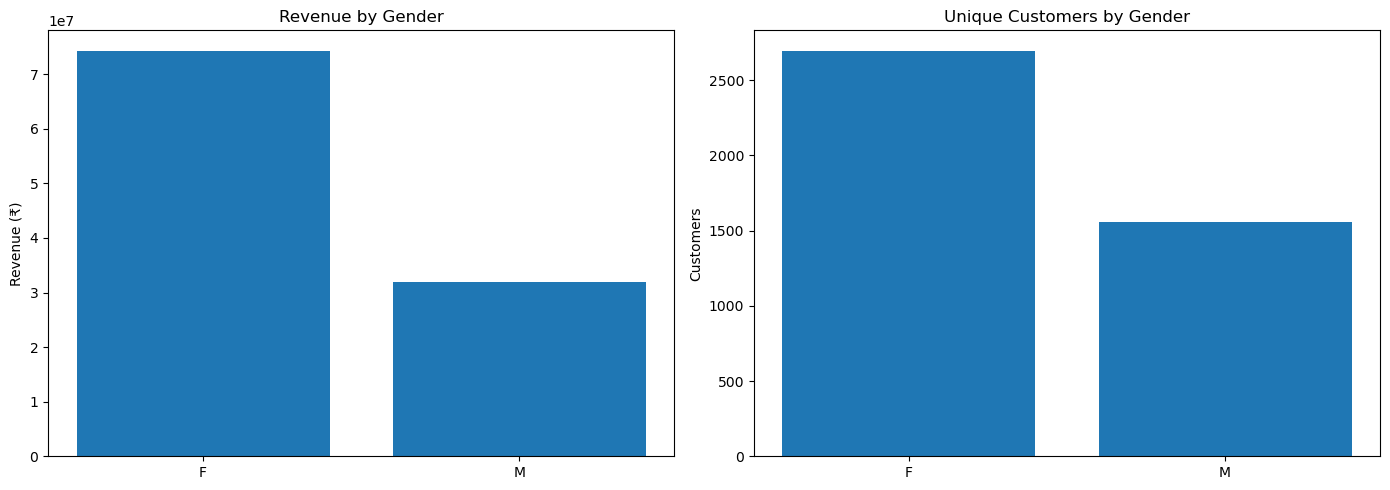

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gender_plot = gender_summary.reset_index()
axes[0].bar(gender_plot["Gender"], gender_plot["Revenue"])
axes[0].set_title("Revenue by Gender")
axes[0].set_xlabel("")
axes[0].set_ylabel("Revenue (₹)")

axes[1].bar(gender_plot["Gender"], gender_plot["Customers"])
axes[1].set_title("Unique Customers by Gender")
axes[1].set_xlabel("")
axes[1].set_ylabel("Customers")

plt.tight_layout()
plt.show()


In [9]:
age_summary = segment_summary("Age Group")
age_summary.round(2)


,Revenue,Orders,Customers,Transactions,Revenue Share %
Age Group,,,,,
26-35,42581767,11378,1386,4536,40.10
36-45,22135135,5683,751,2282,20.85
18-25,17235530,4646,652,1878,16.23
46-50,9207844,2371,328,983,8.67
51-55,8237909,2111,300,829,7.76
55+,4080987,1076,203,427,3.84
0-17,2699653,690,132,296,2.54


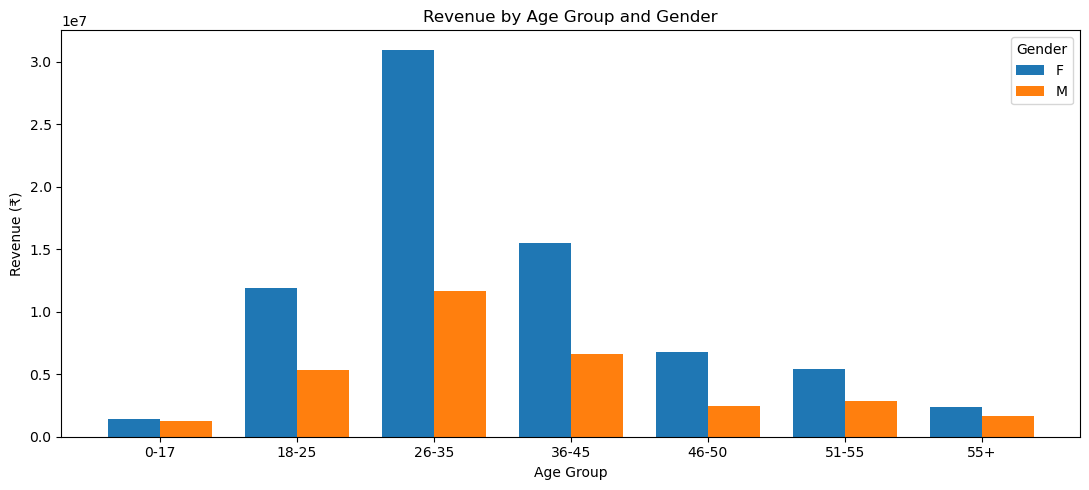

In [10]:
age_gender = (
    df.groupby(["Age Group", "Gender"])
    .agg(Revenue=("Amount", "sum"), Orders=("Orders", "sum"), Customers=("User_ID", "nunique"))
    .reset_index()
)

age_order = ["0-17", "18-25", "26-35", "36-45", "46-50", "51-55", "55+"]
age_gender["Age Group"] = pd.Categorical(age_gender["Age Group"], categories=age_order, ordered=True)
age_gender = age_gender.sort_values("Age Group")

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(age_order))
width = 0.38
for i, gender in enumerate(sorted(age_gender["Gender"].unique())):
    vals = (
        age_gender[age_gender["Gender"] == gender]
        .set_index("Age Group")["Revenue"]
        .reindex(age_order)
        .fillna(0)
    )
    ax.bar(x + (i - 0.5) * width, vals, width, label=gender)

ax.set_xticks(x)
ax.set_xticklabels(age_order)
ax.set_title("Revenue by Age Group and Gender")
ax.set_xlabel("Age Group")
ax.set_ylabel("Revenue (₹)")
ax.legend(title="Gender")
plt.tight_layout()
plt.show()


In [11]:
marital_summary = segment_summary("Marital_Status")
marital_summary.index = marital_summary.index.map({0: "Single", 1: "Married"})
marital_summary.round(2)


,Revenue,Orders,Customers,Transactions,Revenue Share %
Marital_Status,,,,,
Single,62098734,16234,2932,6514,58.49
Married,44080091,11721,2441,4717,41.51


### Customer profile findings

- Female customers account for the largest share of revenue in this dataset.
- The **26–35** age group is the strongest age segment by revenue.
- The largest individual demographic combination is **female customers aged 26–35**.
- The revenue mix is not evenly distributed across age groups, suggesting that campaign targeting can be prioritized rather than treating all customers equally.
- Marital status shows a meaningful revenue split, but it should be treated as a descriptive characteristic rather than a causal driver.


## 4. Geographic performance

### Business questions
- Which states generate the most revenue?
- Does the ranking by revenue match the ranking by order volume?
- Which zones contribute most to the overall sales mix?

This helps identify regions where marketing, inventory, and campaign investment may have the greatest potential impact.


In [12]:
state_summary = segment_summary("State")
state_top10 = state_summary.head(10)
state_top10.round(2)


,Revenue,Orders,Customers,Transactions,Revenue Share %
State,,,,,
Uttar Pradesh,19346055,4803,1423,1942,18.22
Maharashtra,14404467,3798,1174,1522,13.57
Karnataka,13523540,3240,1043,1304,12.74
Delhi,11603818,2740,884,1104,10.93
Madhya Pradesh,8101142,2252,777,921,7.63
Andhra Pradesh,8037146,2051,704,811,7.57
Himachal Pradesh,4963368,1568,536,608,4.67
Haryana,4217871,1106,418,451,3.97
Bihar,4014669,1058,406,433,3.78


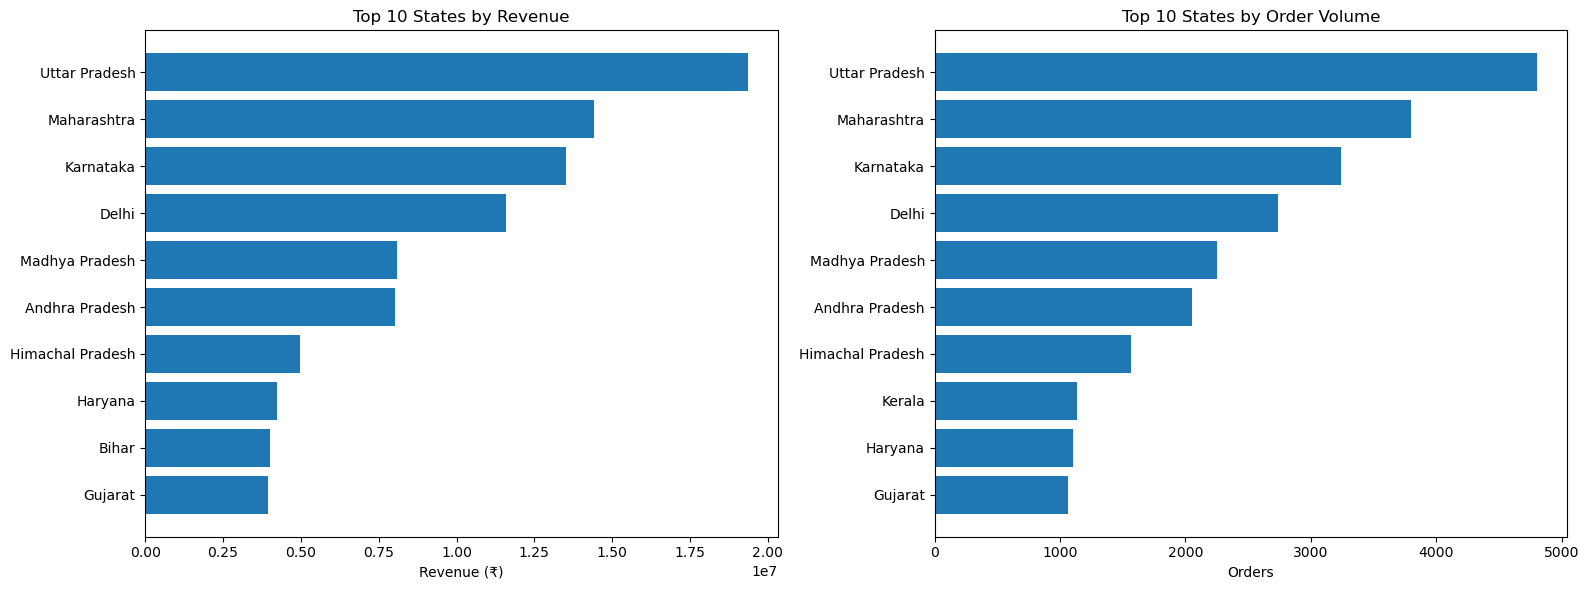

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_data = state_top10.sort_values("Revenue")
axes[0].barh(plot_data.index, plot_data["Revenue"])
axes[0].set_title("Top 10 States by Revenue")
axes[0].set_xlabel("Revenue (₹)")
axes[0].set_ylabel("")

plot_data_orders = state_summary.sort_values("Orders", ascending=False).head(10).sort_values("Orders")
axes[1].barh(plot_data_orders.index, plot_data_orders["Orders"])
axes[1].set_title("Top 10 States by Order Volume")
axes[1].set_xlabel("Orders")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


In [14]:
zone_summary = segment_summary("Zone")
zone_summary.round(2)


,Revenue,Orders,Customers,Transactions,Revenue Share %
Zone,,,,,
Central,41571959,10619,2378,4287,39.15
Southern,26606667,6740,1790,2693,25.06
Western,18342626,4861,1415,1948,17.28
Northern,12616448,3724,1134,1490,11.88
Eastern,7041125,2011,708,813,6.63


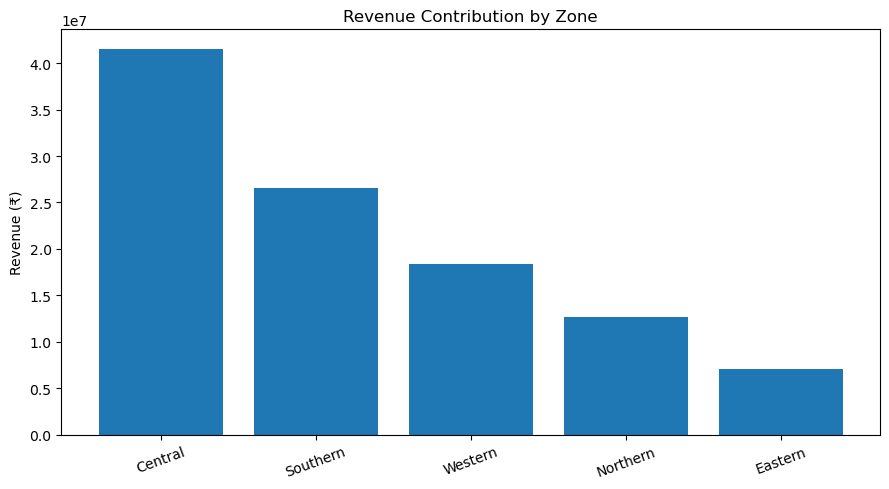

In [15]:
plt.figure(figsize=(9, 5))
zone_plot = zone_summary.reset_index()
plt.bar(zone_plot["Zone"], zone_plot["Revenue"])
plt.title("Revenue Contribution by Zone")
plt.xlabel("")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Geographic findings

- **Uttar Pradesh, Maharashtra, and Karnataka** are the three largest states by revenue.
- The **Central zone** contributes the largest share of revenue among the available zones.
- The state ranking by revenue and order volume is broadly aligned, which suggests that the leading markets are driven by both transaction activity and sales value.
- Geographic concentration means campaigns and inventory planning can be prioritized around the strongest markets while still testing growth opportunities in smaller regions.


## 5. Occupation and customer segments

Occupation provides another way to understand the customer base. The objective is not to claim that an occupation causes higher spending, but to identify customer groups that contribute a larger share of observed revenue.


In [16]:
occupation_summary = segment_summary("Occupation")
occupation_summary.head(10).round(2)


,Revenue,Orders,Customers,Transactions,Revenue Share %
Occupation,,,,,
IT Sector,14741862,3989,1125,1581,13.88
Healthcare,13034586,3455,1039,1408,12.28
Aviation,12599994,3212,972,1309,11.87
Banking,10770610,2817,860,1137,10.14
Govt,8517212,2155,679,854,8.02
Hospitality,6337633,1731,571,700,5.97
Media,6295832,1596,525,637,5.93
Automobile,5368596,1371,465,565,5.06
Chemical,5297436,1309,454,541,4.99


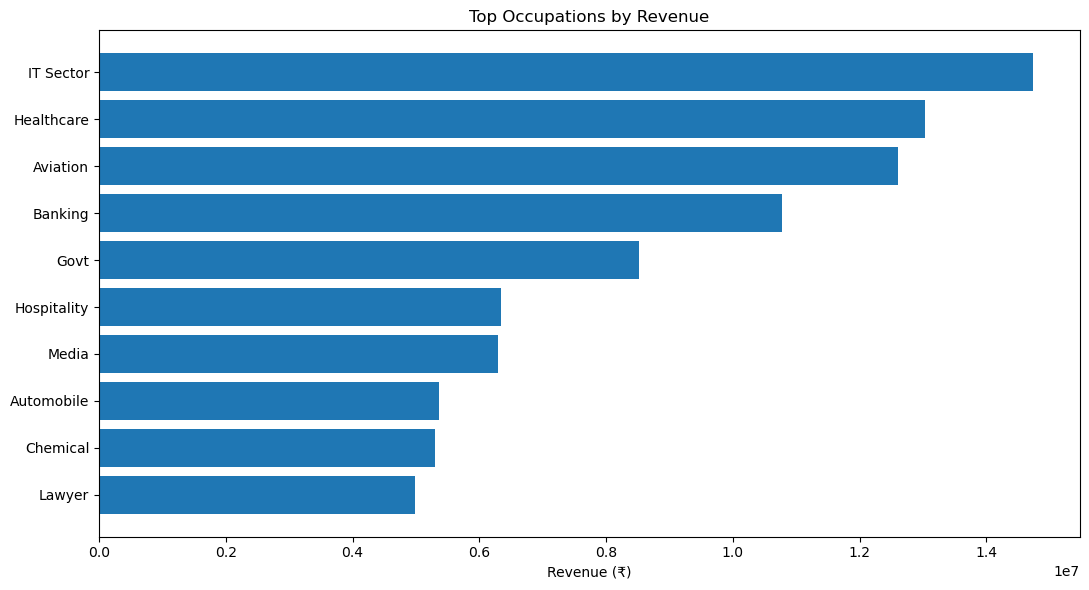

In [17]:
occupation_top = occupation_summary.head(10).sort_values("Revenue")

plt.figure(figsize=(11, 6))
plt.barh(occupation_top.index, occupation_top["Revenue"])
plt.title("Top Occupations by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [18]:
occupation_gender = (
    df.groupby(["Occupation", "Gender"])["Amount"]
    .sum()
    .reset_index()
)


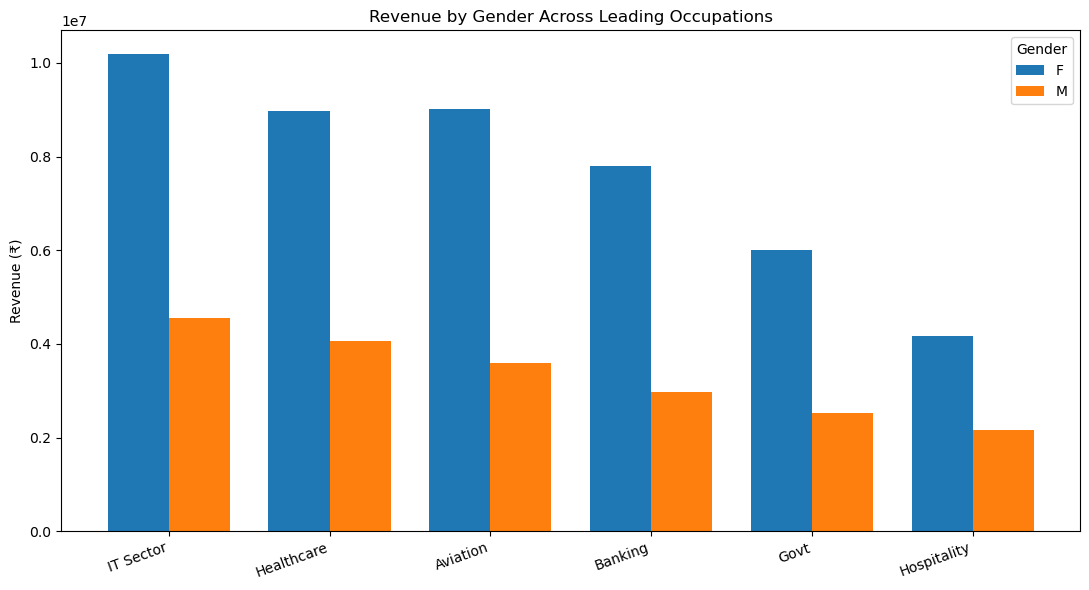

In [19]:
top_occupations = occupation_summary.head(6).index
plot_df = occupation_gender[occupation_gender["Occupation"].isin(top_occupations)].copy()
pivot = plot_df.pivot(index="Occupation", columns="Gender", values="Amount").fillna(0)
pivot = pivot.loc[top_occupations.intersection(pivot.index)]

x = np.arange(len(pivot.index))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
for i, gender in enumerate(pivot.columns):
    ax.bar(x + (i - (len(pivot.columns)-1)/2)*width, pivot[gender], width, label=gender)

ax.set_xticks(x)
ax.set_xticklabels(pivot.index, rotation=20, ha="right")
ax.set_title("Revenue by Gender Across Leading Occupations")
ax.set_xlabel("")
ax.set_ylabel("Revenue (₹)")
ax.legend(title="Gender")
plt.tight_layout()
plt.show()


### Occupation findings

- **IT Sector, Healthcare, and Aviation** are among the strongest occupation groups by revenue.
- Female customers contribute a substantial portion of revenue across the leading occupations.
- The occupation analysis can support audience segmentation for future campaigns, but the dataset does not contain marketing exposure or conversion data, so campaign effectiveness cannot be measured directly.


## 6. Product performance

### Business questions
- Which categories drive the most revenue?
- Which categories generate the most order volume?
- Are the highest-revenue categories also the highest-volume categories?
- Which individual products have the largest revenue contribution?

Comparing revenue and orders is important because a category can have many orders without being the largest revenue contributor.


In [20]:
category_summary = segment_summary("Product_Category")
category_summary.round(2)


,Revenue,Orders,Customers,Transactions,Revenue Share %
Product_Category,,,,,
Food,33933883,6110,1698,2490,31.96
Clothing & Apparel,16484472,6627,1757,2653,15.53
Electronics & Gadgets,15607657,5208,1410,2082,14.70
Footwear & Shoes,15575209,2646,798,1059,14.67
Furniture,5440051,889,330,352,5.12
Games & Toys,4331694,940,354,386,4.08
Sports Products,3635933,870,338,356,3.42
Beauty,1959484,1086,391,422,1.85
Auto,1935041,238,95,96,1.82


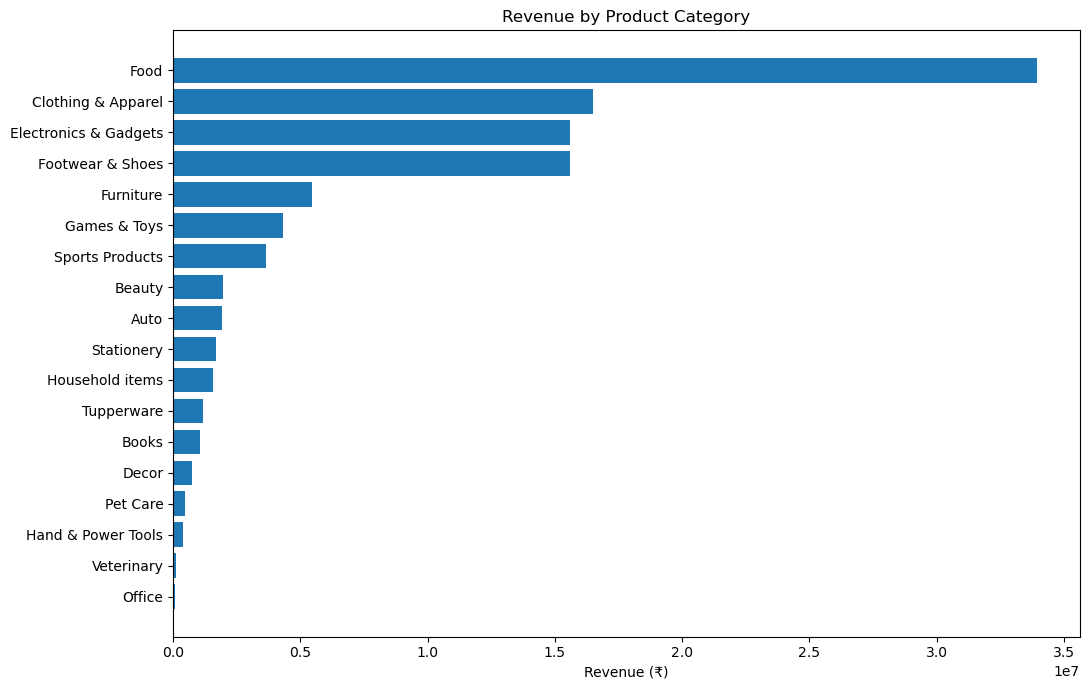

In [21]:
category_plot = category_summary.reset_index().sort_values("Revenue")

plt.figure(figsize=(11, 7))
plt.barh(category_plot["Product_Category"], category_plot["Revenue"])
plt.title("Revenue by Product Category")
plt.xlabel("Revenue (₹)")
plt.ylabel("")
plt.tight_layout()
plt.show()


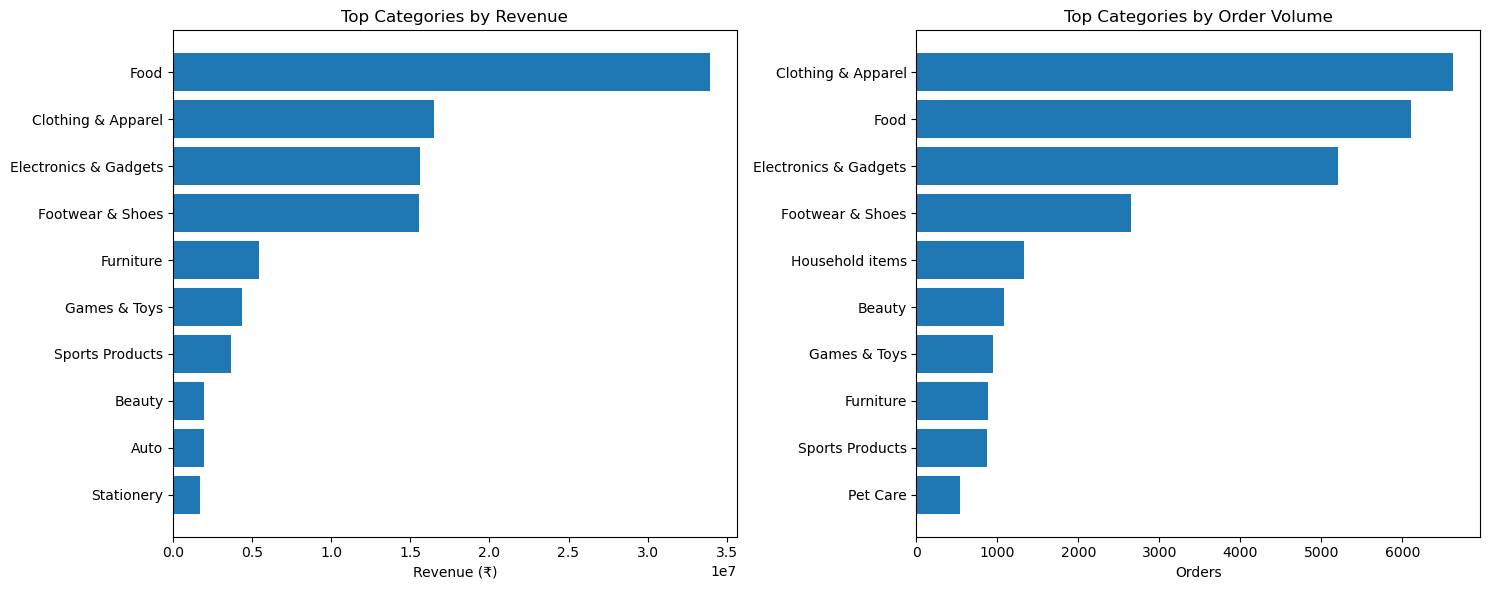

In [22]:
category_orders = category_summary.sort_values("Orders", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rev_plot = category_summary.head(10).sort_values("Revenue")
axes[0].barh(rev_plot.index, rev_plot["Revenue"])
axes[0].set_title("Top Categories by Revenue")
axes[0].set_xlabel("Revenue (₹)")
axes[0].set_ylabel("")

order_plot = category_orders.head(10).sort_values("Orders")
axes[1].barh(order_plot.index, order_plot["Orders"])
axes[1].set_title("Top Categories by Order Volume")
axes[1].set_xlabel("Orders")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


In [23]:
top_products = (
    df.groupby("Product_ID")
    .agg(
        Revenue=("Amount", "sum"),
        Orders=("Orders", "sum"),
        Customers=("User_ID", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

top_products["Revenue Share %"] = top_products["Revenue"] / total_revenue * 100
top_products.head(10).round(2)


,Revenue,Orders,Customers,Revenue Share %
Product_ID,,,,
P00265242,540136,127,52,0.51
P00110942,424833,116,44,0.40
P00184942,401816,82,36,0.38
P00112142,341020,64,33,0.32
P00059442,338571,70,28,0.32
P00237542,322363,91,35,0.30
P00058042,307040,72,25,0.29
P00110742,294548,73,30,0.28
P00110842,290661,74,30,0.27


### Product findings

- **Food** is the largest revenue-generating category in the dataset.
- Clothing & Apparel, Electronics & Gadgets, and Footwear & Shoes form the next major revenue groups.
- Category rankings by revenue and order volume are not identical, which is useful for separating high-volume demand from high-value sales.
- Individual product revenue is distributed across many product IDs; the top product contributes only a small fraction of total revenue, indicating relatively low dependence on a single SKU.


## 7. Customer concentration and repeat behavior

A useful portfolio analysis should also ask whether revenue depends heavily on a small number of customers.

Because the dataset contains a `User_ID`, we can compare customer-level revenue and order activity.


In [24]:
customer_summary = (
    df.groupby("User_ID")
    .agg(
        Revenue=("Amount", "sum"),
        Orders=("Orders", "sum"),
        Transactions=("Product_ID", "size"),
        Products=("Product_ID", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

customer_summary["Revenue Share %"] = customer_summary["Revenue"] / total_revenue * 100

customer_summary.head(10).round(2)


,Revenue,Orders,Transactions,Products,Revenue Share %
User_ID,,,,,
1001680,281034,58,24,24,0.26
1001941,239147,52,22,22,0.23
1003476,220435,57,19,18,0.21
1002665,201104,50,19,18,0.19
1003808,197660,55,23,21,0.19
1004425,194343,48,20,20,0.18
1003618,189921,39,16,16,0.18
1000424,187679,48,19,19,0.18
1004682,185122,51,19,19,0.17


In [25]:
customer_revenue_quantiles = customer_summary["Revenue"].quantile([0.50, 0.75, 0.90, 0.95, 0.99])
customer_revenue_quantiles.rename("Revenue per Customer").to_frame()


,Revenue per Customer
0.50,"19,410.50"
0.75,"36,316.00"
0.90,"62,488.70"
0.95,"85,891.35"
0.99,"132,612.29"


In [26]:
# Revenue concentration: share generated by the top customer groups
concentration = pd.DataFrame({
    "Customer Group": ["Top 1%", "Top 5%", "Top 10%", "Top 25%"],
    "Revenue Share %": [
        customer_summary.head(max(1, int(np.ceil(len(customer_summary)*0.01))))["Revenue"].sum() / total_revenue * 100,
        customer_summary.head(max(1, int(np.ceil(len(customer_summary)*0.05))))["Revenue"].sum() / total_revenue * 100,
        customer_summary.head(max(1, int(np.ceil(len(customer_summary)*0.10))))["Revenue"].sum() / total_revenue * 100,
        customer_summary.head(max(1, int(np.ceil(len(customer_summary)*0.25))))["Revenue"].sum() / total_revenue * 100,
    ]
})
concentration.round(2)


,Customer Group,Revenue Share %
0,Top 1%,6.00
1,Top 5%,20.59
2,Top 10%,33.32
3,Top 25%,58.20


## 8. Correlation and diagnostic view

Correlation is used here as a diagnostic tool rather than proof of causation. It helps show how the numerical variables in the dataset move relative to one another.


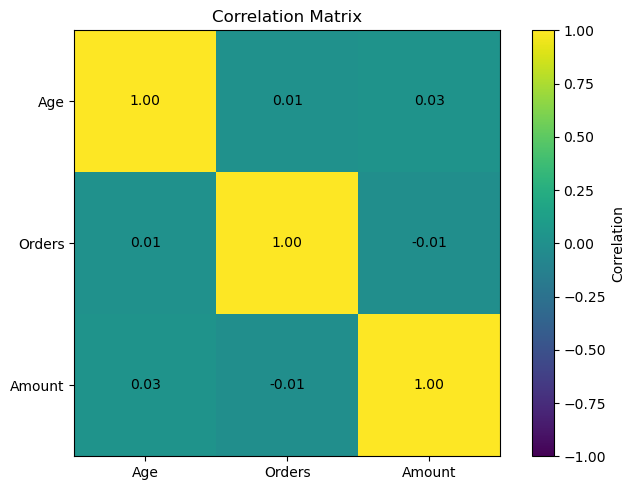

,Age,Orders,Amount
Age,1.00,0.01,0.03
Orders,0.01,1.00,-0.01
Amount,0.03,-0.01,1.00


In [27]:
numeric_cols = ["Age", "Orders", "Amount"]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr.values, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns)
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Matrix")
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

corr


## 9. Key findings

### Customer profile
- Female customers generate the majority of recorded revenue.
- The **26–35 age group** is the strongest age segment.
- Female customers aged 26–35 are the largest demographic revenue combination.

### Geography
- **Uttar Pradesh, Maharashtra, and Karnataka** lead the states by revenue.
- The **Central zone** has the largest overall revenue contribution.

### Occupation
- IT Sector, Healthcare, and Aviation are among the leading occupation groups.
- Female customers account for a particularly strong share within several high-revenue occupations.

### Products
- **Food** is the largest revenue category.
- Clothing & Apparel, Electronics & Gadgets, and Footwear & Shoes are also major contributors.
- Revenue is spread across many product IDs, reducing dependence on a single product.

### Customer concentration
- The customer-level analysis can identify high-value segments and concentration, which is useful for retention and campaign planning.


## 10. Business recommendations

### 1. Prioritize the 26–35 customer segment
This segment contributes the largest share of recorded revenue. Campaigns for this audience can focus on bundles, seasonal offers, and category cross-selling.

### 2. Strengthen high-performing markets
Uttar Pradesh, Maharashtra, and Karnataka should receive attention in regional promotions and inventory planning because they contribute a large share of observed sales.

### 3. Use category-specific promotions
Food is the strongest revenue category, while Clothing & Apparel, Electronics & Gadgets, and Footwear & Shoes are also major contributors. Promotions can be designed around combinations of these categories rather than treating the catalogue uniformly.

### 4. Build occupation-based audience segments
The strongest occupation groups can be used as descriptive audience segments for campaign experimentation. Future data should include campaign exposure and conversion metrics to determine whether these segments actually respond better.

### 5. Protect and grow high-value customers
Customer-level revenue analysis can support retention strategies such as personalized offers and repeat-purchase campaigns.

### 6. Improve future measurement
To move from descriptive EDA toward decision-grade analytics, future datasets should include transaction date/time, discount, product price, cost, profit, campaign source, customer acquisition channel, and repeat-purchase history.


## 11. Limitations

- The dataset is a historical snapshot and does not provide a time series for trend or seasonality analysis.
- There is no cost or margin field, so the analysis measures **revenue**, not profitability.
- There is no campaign exposure or conversion information, so marketing effectiveness cannot be measured.
- The data does not establish causal relationships between customer characteristics and purchasing behavior.
- The `Orders` field is treated as the supplied order-count measure; the raw dataset structure should be confirmed with the data owner before using it as a strict order identifier.


## Conclusion

The analysis shows a clear concentration of recorded Diwali sales among **female customers, especially the 26–35 age group**, with strong contributions from **Uttar Pradesh, Maharashtra, and Karnataka**. Food is the leading revenue category, while IT Sector, Healthcare, and Aviation are among the strongest occupation segments.

The most useful business opportunity is not simply to identify the largest category or customer group, but to combine **demographic, geographic, occupation, and product insights** into targeted campaigns and inventory decisions.

This notebook demonstrates an end-to-end analytics workflow: **data quality → KPI definition → segmentation → visualization → diagnostic analysis → business recommendations**.
